# Quick, Draw!

Колпаков Марк Алексеевич, ДЗ 2.

0.777 — выглядит круто.

Нужно определить, что нарисовано на картинке. Всего 345 классов.
Результат на Kaggle — 0.77700.

## 1. Библиотеки и настройки

In [1]:
import copy
import csv
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights
from torchvision.models import efficientnet_v2_m, EfficientNet_V2_M_Weights

learn = False
calc = False
device = torch.device('cuda' if learn or calc else 'cpu')

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if learn or calc:
    torch.cuda.manual_seed_all(42)
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
if learn or calc:
    assert torch.cuda.is_available(), 'Нужна видеокарта с CUDA'

data = Path('data')
out = Path('run')
os.environ['TORCH_HOME'] = str(Path('cache').resolve())
out.mkdir(exist_ok=True)
print(torch.__version__)
print(device)


2.7.1+cu126
cpu


Обычный запуск показывает сохранённые результаты. `calc = True` заново считает ответы на GPU. `learn = True` включает обучение.

При расчёте ответов включён одинаковый режим cuDNN: [PyTorch](https://docs.pytorch.org/docs/2.7/notes/randomness.html).


## 2. Данные

Убираю повторы и спорные метки. Train нужен для обучения, eval — для выбора настроек, test — для последней проверки. Данные Kaggle с неизвестными ответами лежат отдельно.

In [2]:
def hashes(x):
    return np.array([hashlib.sha256(v.tobytes()).hexdigest() for v in x])

def prepare(data, out):
    data, out = Path(data), Path(out)
    out.mkdir(parents=True, exist_ok=True)
    x = np.load(data / 'train_images.npy', mmap_mode='r')
    y = np.load(data / 'train_labels.npy')
    v = np.load(data / 'val_images.npy', mmap_mode='r')
    z = np.load(data / 'val_labels.npy')
    t = np.load(data / 'test_images.npy', mmap_mode='r')
    names = np.load(data / 'classes.npy')
    assert x.shape == (len(y), 784) and v.shape == (len(z),784)
    assert x.dtype == v.dtype == t.dtype == np.uint8
    assert y.min() == z.min() == 0
    assert y.max() == z.max() == len(names)-1
    h, j, k = hashes(x), hashes(v), hashes(t)
    bad = set()
    seen = {}
    for key, label in zip(h, y):
        if key in seen and seen[key] != label:
            bad.add(key)
        seen[key] = label
    _, first = np.unique(h, return_index=True)
    tr = np.sort(first[~np.isin(h[first], np.concatenate([j, k, list(bad)]))])
    seen = {}
    bad = set(k)
    for key, label in zip(j,z):
        if key in seen and seen[key] != label:
            bad.add(key)
        seen[key] = label
    _, first = np.unique(j, return_index=True)
    first = first[~np.isin(j[first], list(bad))]
    rng = np.random.default_rng(42)
    ev, te = [], []
    for label in range(len(names)):
        ids = first[z[first] == label].copy()
        rng.shuffle(ids)
        ev.extend(ids[:len(ids)//2])
        te.extend(ids[len(ids)//2:])
    ev, te = np.sort(ev), np.sort(te)
    assert len(np.intersect1d(h[tr],j[ev])) == 0
    assert len(np.intersect1d(h[tr],j[te])) == 0
    assert len(np.intersect1d(j[ev],j[te])) == 0
    np.savez(out / 'split.npz', tr=tr, ev=ev, te=te)
    report = {
        'seed':42, 'train':len(tr), 'eval':len(ev), 'test':len(te),
        'kaggle_test':len(t), 'classes':len(names),
        'train_removed':len(x)-len(tr), 'val_removed':len(v)-len(ev)-len(te),
        'overlap_train_val':len(np.intersect1d(h,j)),
        'overlap_train_kaggle':len(np.intersect1d(h,k)),
        'overlap_val_kaggle':len(np.intersect1d(j,k)),
        'files':{}
    }
    for p in sorted(data.glob('*.npy')):
        s = hashlib.sha256()
        with p.open('rb') as f:
            for block in iter(lambda:f.read(1024*1024), b''):
                s.update(block)
        report['files'][p.name] = s.hexdigest()
    (out/'data.json').write_text(json.dumps(report,indent=2), encoding='utf-8')
    print(json.dumps(report,indent=2))

In [3]:
if not (out/'split.npz').exists():
    prepare(data,out)
info = json.loads((out/'data.json').read_text(encoding='utf-8'))
print({k:v for k,v in info.items() if k!='files'})
for name,value in info['files'].items():
    if not (data/name).exists():
        assert not learn and name=='train_images.npy', name
        continue
    s = hashlib.sha256()
    with (data/name).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):
            s.update(block)
    assert s.hexdigest()==value, name
split = np.load(out/'split.npz')
x = np.load(data/'train_images.npy',mmap_mode='r') if learn else None
y = np.load(data/'train_labels.npy')
val = np.load(data/'val_images.npy',mmap_mode='r')
z = np.load(data/'val_labels.npy')
names = np.load(data/'classes.npy')
print('train',len(split['tr']),'eval',len(split['ev']),'test',len(split['te']))


{'seed': 42, 'train': 586386, 'eval': 51742, 'test': 51746, 'kaggle_test': 172500, 'classes': 345, 'train_removed': 114, 'val_removed': 12, 'overlap_train_val': 14, 'overlap_train_kaggle': 18, 'overlap_val_kaggle': 8}
train 586386 eval 51742 test 51746


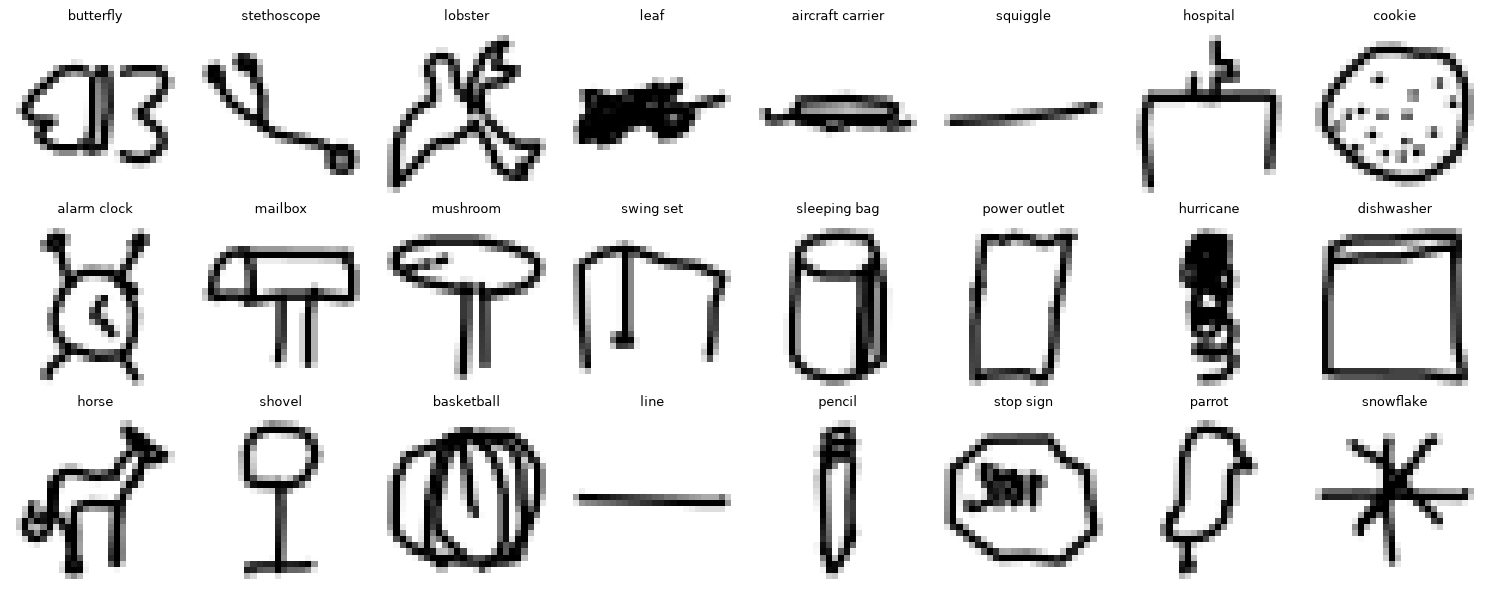

In [4]:
ids = np.random.default_rng(42).choice(split['ev'],24,replace=False)
fig,ax = plt.subplots(3,8,figsize=(15,6))
for a,i in zip(ax.flat,ids):
    a.imshow(val[i].reshape(28,28),cmap='gray_r')
    a.set_title(names[z[i]],fontsize=9)
    a.axis('off')
plt.tight_layout()
plt.show()


## 3. Подготовка картинок

Выравниваю рисунок и добавляю поля. При обучении немного поворачиваю, сдвигаю и отражаю картинки. Ещё пробую менять толщину линий и слегка искривлять рисунок.

In [5]:
def views(x, a):
    x = x.reshape(-1,1,28,28).float()/255
    if a['kind'] == 'base':
        return x*2-1
    raw = F.pad(x,(2,2,2,2))
    if a['view'] in ['pair','center']:
        mask = x[:,0] > 0.05
        cols, rows = mask.any(1), mask.any(2)
        pos = torch.arange(28,device=x.device)[None]
        left = torch.where(cols,pos,28).amin(1)
        right = torch.where(cols,pos,-1).amax(1)
        top = torch.where(rows,pos,28).amin(1)
        bottom = torch.where(rows,pos,-1).amax(1)
        scale = (torch.maximum(right-left+1,bottom-top+1)+4).clamp(5,32)/28
        theta = torch.zeros(len(x),2,3,device=x.device)
        theta[:,0,0] = theta[:,1,1] = scale
        theta[:,0,2] = (left+right+1)/28-1
        theta[:,1,2] = (top+bottom+1)/28-1
        grid = F.affine_grid(theta,(len(x),1,32,32),align_corners=False)
        center = F.grid_sample(x,grid,align_corners=False)
        raw = torch.cat([raw,center],1) if a['view'] == 'pair' else center
    if a['kind'] in ['res','conv','v2','v2m']:
        raw = 1-F.interpolate(raw,size=a['size'],mode='bilinear',align_corners=False)
        raw = raw.repeat(1,3,1,1)
        mean = raw.new_tensor([0.485,0.456,0.406])[None,:,None,None]
        std = raw.new_tensor([0.229,0.224,0.225])[None,:,None,None]
        return (raw-mean)/std
    if a['kind'] == 'fast' and a.get('size',32) != 32:
        raw = F.interpolate(raw,size=a['size'],mode='bilinear',align_corners=False)
    return raw

def augment(x, strength=1.0, bend=0.):
    n = len(x)
    r = (torch.rand(n,device=x.device)-0.5)*0.42*strength
    scale = 1+(torch.rand(n,device=x.device)-0.5)*0.22*strength
    flip = torch.where(torch.rand(n,device=x.device)<0.5,-1.,1.)
    theta = torch.zeros(n,2,3,device=x.device)
    theta[:,0,0] = r.cos()*scale*flip
    theta[:,0,1] = -r.sin()*scale+(torch.rand(n,device=x.device)-0.5)*0.12*strength
    theta[:,1,0] = r.sin()*scale*flip
    theta[:,1,1] = r.cos()*scale
    theta[:,:,2] = (torch.rand(n,2,device=x.device)-0.5)*0.15*strength
    grid = F.affine_grid(theta,x.shape,align_corners=False)
    if bend:
        noise = torch.rand(n,2,4,4,device=x.device)*2-1
        noise = F.interpolate(noise,size=x.shape[-2:],mode='bilinear',align_corners=False)
        grid = grid+bend*noise.permute(0,2,3,1)
    return F.grid_sample(x,grid,align_corners=False)

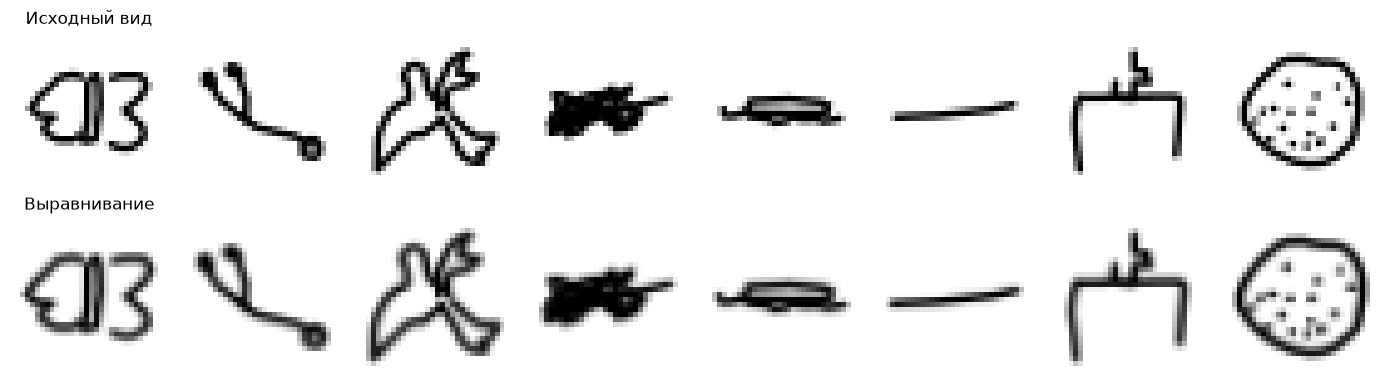

In [6]:
a = {'kind':'fast','view':'pair','size':32}
b = views(torch.from_numpy(np.array(val[ids[:8]],copy=True)).to(device),a).cpu().numpy()
fig,ax = plt.subplots(2,8,figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(b[i,0],cmap='gray_r')
    ax[1,i].imshow(b[i,1],cmap='gray_r')
    ax[0,i].axis('off')
    ax[1,i].axis('off')
ax[0,0].set_title('Исходный вид')
ax[1,0].set_title('Выравнивание')
plt.tight_layout()
plt.show()
del b


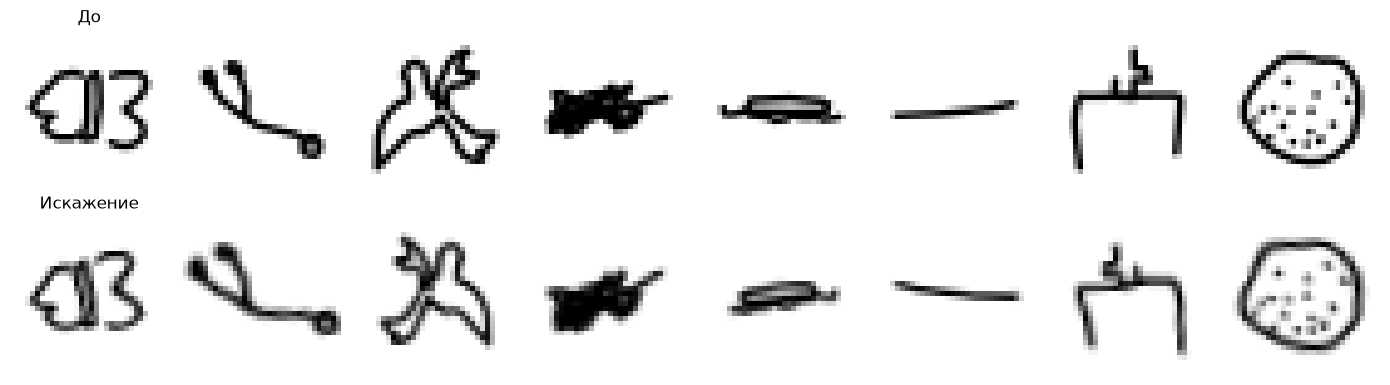

In [7]:
b = views(torch.from_numpy(np.array(val[ids[:8]],copy=True)).to(device),
          {'kind':'fast','view':'pair','size':32})
c = augment(b,1.05,0.06)
fig,ax = plt.subplots(2,8,figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(b[i,0].cpu(),cmap='gray_r')
    ax[1,i].imshow(c[i,0].cpu(),cmap='gray_r')
    ax[0,i].axis('off')
    ax[1,i].axis('off')
ax[0,0].set_title('До')
ax[1,0].set_title('Искажение')
plt.tight_layout()
plt.show()
del b,c


### Толщина линий

Пример утолщения и истончения для line.

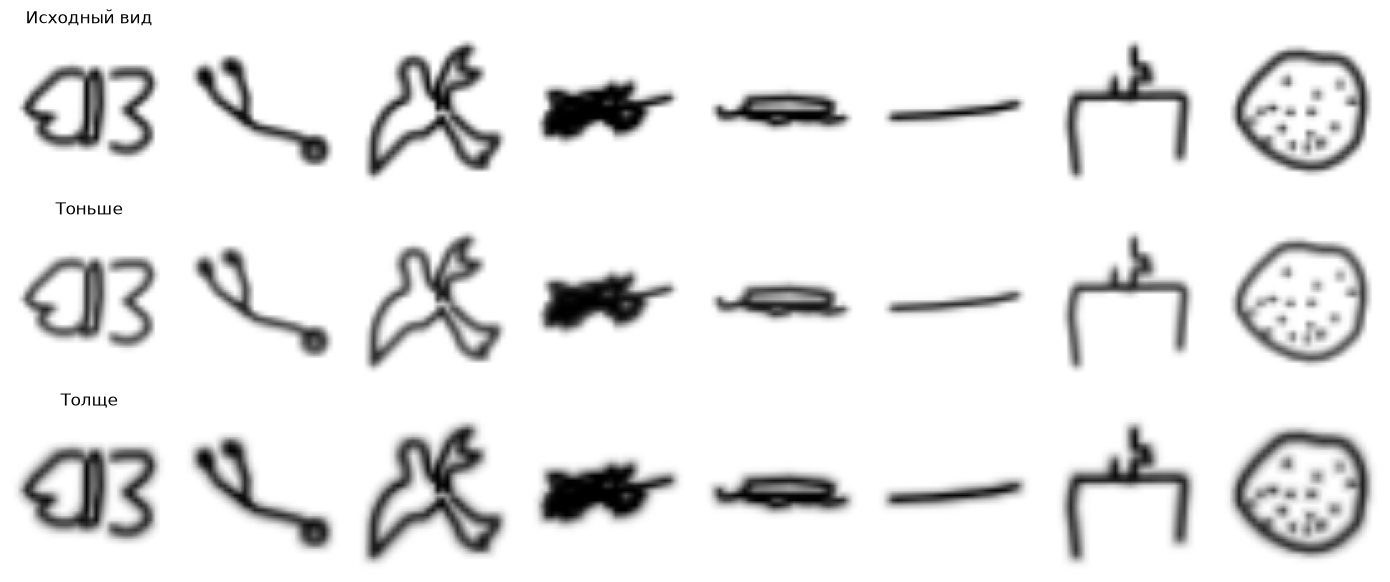

In [8]:
b = views(torch.from_numpy(np.array(val[ids[:8]],copy=True)).to(device),
          {'kind':'conv','view':'center','size':96})
thin = 0.8*b+0.2*F.max_pool2d(b,7,1,3)
thick = 0.8*b-0.2*F.max_pool2d(-b,7,1,3)
fig,ax = plt.subplots(3,8,figsize=(14,6))
for j,c in enumerate([b,thin,thick]):
    for i in range(8):
        image = c[i,0].cpu()*0.229+0.485
        ax[j,i].imshow(image,cmap='gray',vmin=0,vmax=1)
        ax[j,i].axis('off')
for a,title in zip(ax[:,0],['Исходный вид','Тоньше','Толще']):
    a.set_title(title)
plt.tight_layout()
plt.show()
del b,thin,thick,c


## 4. Модели

Проверяю ResNet18, ConvNeXt Tiny и EfficientNetV2-S/M с весами ImageNet. Последний слой меняю под 345 классов. Ещё есть маленькая сеть с частичными свёртками по идее FasterNet.

In [9]:
class FastBlock(nn.Module):
    def __init__(self,c):
        super().__init__()
        self.n = c//4
        self.conv = nn.Conv2d(self.n,self.n,3,1,1,bias=False)
        self.mix = nn.Sequential(
            nn.Conv2d(c,c*2,1,bias=False), nn.BatchNorm2d(c*2), nn.ReLU(),
            nn.Conv2d(c*2,c,1,bias=False)
        )

    def forward(self,x):
        a,b = torch.split(x,[self.n,x.shape[1]-self.n],dim=1)
        y = torch.cat([self.conv(a),b],dim=1)
        return x+self.mix(y)

class FastNet(nn.Module):
    def __init__(self,channels=2,classes=345,width=32):
        super().__init__()
        layers = [nn.Conv2d(channels,width,3,2,1,bias=False),nn.BatchNorm2d(width)]
        for i,depth in enumerate([2,2,6,2]):
            c = width*2**i
            if i:
                layers.extend([nn.Conv2d(c//2,c,2,2,bias=False),nn.BatchNorm2d(c)])
            for j in range(depth):
                layers.append(FastBlock(c))
        self.body = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Dropout(0.15),nn.Linear(width*16,classes))
        for m in self.modules():
            if isinstance(m,nn.Conv2d):
                nn.init.kaiming_normal_(m.weight,mode='fan_out',nonlinearity='relu')

    def forward(self,x):
        x = self.body(x)
        a = F.adaptive_avg_pool2d(x,1).flatten(1)
        b = F.adaptive_max_pool2d(x,1).flatten(1)
        return self.head(torch.cat([a,b],dim=1))

In [10]:
def make(a, pretrained=False):
    if a['kind'] in ['v2','v2m']:
        if a['kind'] == 'v2m':
            m = efficientnet_v2_m(weights=EfficientNet_V2_M_Weights.DEFAULT if pretrained else None)
        else:
            m = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT if pretrained else None)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features,a['classes'])
        return m
    if a['kind'] == 'conv':
        m = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features,a['classes'])
        return m
    if a['kind'] == 'fast':
        return FastNet(2 if a['view']=='pair' else 1,a['classes'],a.get('width',32))
    if a['kind'] == 'base':
        m = resnet18(num_classes=a['classes'])
        m.conv1 = nn.Conv2d(1,64,7,2,3,bias=False)
        return m
    if a['kind'] == 'res':
        m = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        if a.get('pool',1) == 0:
            m.maxpool = nn.Identity()
        m.fc = nn.Linear(m.fc.in_features,a['classes'])
        return m
    raise ValueError(a['kind'])

## 5. Проверка

На eval сравниваю обычный ответ и средний ответ для нескольких версий картинки: с отражением, сдвигом, поворотом или другим масштабом.

In [11]:
@torch.inference_mode()
@torch.backends.cudnn.flags(enabled=True,benchmark=False,deterministic=True)
def predict(m, x, a, batch=512, flip=False, shift=False, rot=False, zoom=False):
    m.eval()
    torch.backends.cuda.matmul.allow_tf32 = True
    result = []
    for i in range(0,len(x),batch):
        b = x[i:i+batch]
        if not isinstance(b,torch.Tensor):
            b = torch.from_numpy(np.array(b,copy=True)).cuda()
        b = views(b,a)
        with torch.autocast('cuda',dtype=torch.float16):
            p = m(b).float().softmax(1)
            count = 1
            if flip:
                p = p+m(b.flip(-1)).float().softmax(1)
                count += 1
            if shift:
                for dim in [2,3]:
                    for step in [-1,1]:
                        p = p+m(b.roll(step,dim)).float().softmax(1)
                        count += 1
            if rot or zoom:
                fill = -1. if a['kind']=='base' else 0.
                if a['kind'] in ['res','conv','v2','v2m']:
                    fill = b.new_tensor([(1-0.485)/0.229,(1-0.456)/0.224,(1-0.406)/0.225])[None,:,None,None]
                cases = []
                if rot:
                    cases += [(-0.07,1.),(0.07,1.)]
                if zoom:
                    cases += [(0.,0.95),(0.,1.05)]
                for r,s in cases:
                    theta = b.new_tensor([[math.cos(r)*s,-math.sin(r)*s,0.],
                                          [math.sin(r)*s,math.cos(r)*s,0.]])
                    theta = theta[None].repeat(len(b),1,1)
                    grid = F.affine_grid(theta,b.shape,align_corners=False)
                    c = F.grid_sample(b-fill,grid,align_corners=False)+fill
                    p = p+m(c).float().softmax(1)
                    count += 1
                    if flip:
                        p = p+m(c.flip(-1)).float().softmax(1)
                        count += 1
            p = p/count
        result.append(p.cpu().numpy())
    return np.concatenate(result)

### BatchNorm

После усреднения весов заново считаю статистики BatchNorm на части train. Вариант выбираю по eval.

In [12]:
@torch.inference_mode()
def calibrate(m, x, a, batch=256):
    m.eval()
    torch.backends.cuda.matmul.allow_tf32 = True
    if not any(isinstance(layer,torch.nn.BatchNorm2d) for layer in m.modules()):
        return
    for layer in m.modules():
        if isinstance(layer,torch.nn.BatchNorm2d):
            layer.reset_running_stats()
            layer.momentum = None
            layer.train()
    for i in range(0,len(x),batch):
        b = x[i:i+batch]
        if not isinstance(b,torch.Tensor):
            b = torch.from_numpy(np.array(b,copy=True)).cuda()
        with torch.autocast('cuda',dtype=torch.float16):
            m(views(b,a).to(memory_format=torch.channels_last))
    m.eval()

### Baseline

In [13]:
saved = json.loads((out/'score.json').read_text(encoding='utf-8'))
base = saved['baseline_eval_acc']
print('Сохранённая baseline eval accuracy:',round(base,6))


Сохранённая baseline eval accuracy: 0.675177


## 6. Обучение

Использую AdamW и плавно меняю learning rate. MixUp смешивает картинки, а EMA усредняет веса во время обучения. Лучшие веса выбираю по eval. После каждой эпохи сохраняю лог.

In [14]:
def train_epoch(m, ema, opt, scaler, x, y, a, epoch):
    steps = len(x)//a['batch'] if a['drop'] else math.ceil(len(x)/a['batch'])
    m.train()
    order = torch.randperm(len(x),device='cuda')
    if a['drop']:
        order = order[:steps*a['batch']]
    total = torch.zeros(3,device='cuda')
    for step,idx in enumerate(order.split(a['batch'])):
        progress = epoch+step/steps
        lr = a['lr']*min(1.,(progress+0.1)/2)*(0.02+0.98*(1+math.cos(math.pi*progress/a['epochs']))/2)
        for group in opt.param_groups:
            group['lr'] = lr*group.get('scale',1.)
        b, label = views(x[idx],a),y[idx]
        if a['kind'] == 'fast':
            strength = 0.6 if epoch >= a['epochs']-4 else 1.
            b = augment(b,strength*a['aug'],a['bend'])
            if random.random() < a['ink']:
                ink = F.max_pool2d(b,3,1,1) if random.random()<0.5 else -F.max_pool2d(-b,3,1,1)
                b = 0.8*b+0.2*ink
        else:
            if a['ink'] and random.random() < a['ink']:
                k = 2*max(1,a['size']//32)+1
                ink = F.max_pool2d(b,k,1,k//2) if random.random()<0.5 else -F.max_pool2d(-b,k,1,k//2)
                b = 0.8*b+0.2*ink
            fill = b.new_tensor([(1-0.485)/0.229,(1-0.456)/0.224,(1-0.406)/0.225])[None,:,None,None]
            b = augment(b-fill,0.7*a['aug'],a['bend'])+fill
        lam = 1.
        if epoch < a['epochs']-a['last'] and random.random() < a['mix']:
            lam = np.random.beta(a['alpha'],a['alpha'])
            lam = max(lam,1-lam)
            perm = torch.randperm(len(b),device='cuda')
            b = b*lam+b[perm]*(1-lam)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda',dtype=torch.float16):
            pred = m(b.to(memory_format=torch.channels_last))
            loss = F.cross_entropy(pred,label,label_smoothing=a['smooth'])
            if lam < 1:
                loss = lam*loss+(1-lam)*F.cross_entropy(pred,label[perm],label_smoothing=a['smooth'])
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(m.parameters(),5.)
        scaler.step(opt)
        scaler.update()
        with torch.no_grad():
            total[0] += loss.detach()*len(b)
            total[1] += (pred.argmax(1)==label).sum()
            total[2] += len(b)
            if step%16 == 0:
                decay = min(a['decay'], (1+epoch*steps+step)/(100+epoch*steps+step))
                for q,r in zip(ema.parameters(),m.parameters()):
                    q.lerp_(r,1-decay)
                for q,r in zip(ema.buffers(),m.buffers()):
                    q.copy_(r)
        if (step+1)%200 == 0:
            print(f'epoch {epoch+1} step {step+1}/{steps}',flush=True)
    return total,lr

In [15]:
def fit(a):
    a = a.copy()
    random.seed(a['seed'])
    np.random.seed(a['seed'])
    torch.manual_seed(a['seed'])
    torch.cuda.manual_seed_all(a['seed'])
    torch.set_num_threads(4)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    data, out = Path(a['data']), Path(a['out'])
    out.mkdir(parents=True,exist_ok=True)
    split = np.load(out/'split.npz')
    ids = split['tr']
    if a['limit']:
        ids = np.random.default_rng(a['seed']).choice(ids,min(a['limit'],len(ids)),replace=False)
    src = np.load(data/'train_images.npy',mmap_mode='r')
    x = torch.from_numpy(src[ids]).cuda()
    y = torch.from_numpy(np.load(data/'train_labels.npy')[ids]).cuda()
    val = np.load(data/'val_images.npy',mmap_mode='r')
    v = torch.from_numpy(val[split['ev']]).cuda()
    ids = np.random.default_rng(42).choice(len(x),min(32768,len(x)),replace=False)
    clean = x[torch.as_tensor(ids,device='cuda')]
    z = np.load(data/'val_labels.npy')[split['ev']]
    a['classes'] = len(np.load(data/'classes.npy'))
    m = make(a,pretrained=a['kind'] in ['res','conv','v2','v2m']).cuda().to(memory_format=torch.channels_last)
    if a['resume']:
        w = torch.load(a['resume'],map_location='cpu',weights_only=True)
        m.load_state_dict(w['model'])
    ema = copy.deepcopy(m).eval()
    for q in ema.parameters():
        q.requires_grad_(False)
    if a['kind'] in ['v2','v2m']:
        groups = [{'params':m.features.parameters(),'scale':a['back']},
                  {'params':m.classifier.parameters(),'scale':1.}]
        opt = torch.optim.AdamW(groups,lr=a['lr'],weight_decay=a['wd'])
    else:
        opt = torch.optim.AdamW(m.parameters(),lr=a['lr'],weight_decay=a['wd'])
    scaler = torch.amp.GradScaler('cuda')
    best = 0
    wait = 0
    steps = len(x)//a['batch'] if a['drop'] else math.ceil(len(x)/a['batch'])
    log = out/(a['name']+'.csv')
    (out/(a['name']+'.json')).write_text(json.dumps(a,indent=2),encoding='utf-8')
    print(json.dumps({'config':a,'train':len(x),'eval':len(v),'steps':steps}),flush=True)
    with log.open('w',newline='',encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch','loss','train_acc','eval_acc','ema_acc','lr','seconds'])
        for epoch in range(a['epochs']):
            start = time.time()
            total,lr = train_epoch(m,ema,opt,scaler,x,y,a,epoch)
            vm,ve = m,ema
            if a['bn']:
                vm,ve = copy.deepcopy(m),copy.deepcopy(ema)
                calibrate(vm,clean,a)
                calibrate(ve,clean,a)
            prob = predict(vm,v,a)
            acc = float((prob.argmax(1)==z).mean())
            ep = predict(ve,v,a)
            ea = float((ep.argmax(1)==z).mean())
            row = [epoch+1,float(total[0]/total[2]),float(total[1]/total[2]),acc,ea,lr,round(time.time()-start,1)]
            writer.writerow(row)
            f.flush()
            print(json.dumps(dict(zip(['epoch','loss','train_acc','eval_acc','ema_acc','lr','seconds'],row))),flush=True)
            if max(acc,ea) > best:
                best = max(acc,ea)
                chosen = ve if ea > acc else vm
                w = {'model':{k:v.detach().cpu() for k,v in chosen.state_dict().items()},'config':a.copy(),'epoch':epoch+1,'eval_acc':best,'ema':ea>acc,'bn_n':len(clean) if a['bn'] else 0}
                torch.save(w,out/(a['name']+'.pt'))
                np.save(out/(a['name']+'_eval.npy'),ep if ea>acc else prob)
                del chosen,w
                wait = 0
            else:
                wait += 1
            del vm,ve,prob,ep
            if a['stop'] and epoch+1 >= a['stop']:
                break
            if a['patience'] and wait >= a['patience'] and epoch >= 10:
                break
    print(f'best eval {best:.6f}',flush=True)

## 7. Опыты

В каждом a задаю настройки одного опыта и добавляю их в jobs. Пробую разные модели, размеры картинок и толщину линий. Логи — run/log.csv.


In [16]:
jobs = []

In [17]:
a = {'data': 'data',
 'out': 'run',
 'name': 'res',
 'kind': 'res',
 'view': 'center',
 'epochs': 20,
 'batch': 384,
 'lr': 0.001,
 'wd': 0.005,
 'mix': 0.15,
 'smooth': 0.04,
 'width': 32,
 'size': 64,
 'seed': 42,
 'limit': 0,
 'resume': '',
 'patience': 7,
 'classes': 345,
 'ink': 0.0,
 'drop': 0,
 'bn': 0,
 'aug': 1.0,
 'bend': 0.0,
 'alpha': 0.2,
 'decay': 0.985,
 'back': 1.0,
 'stop': 0,
 'last': 4}
jobs.append(a)

In [18]:
a = {'data': 'data',
 'out': 'run',
 'name': 'fast',
 'kind': 'fast',
 'view': 'pair',
 'epochs': 30,
 'batch': 384,
 'lr': 0.002,
 'wd': 0.005,
 'mix': 0.15,
 'smooth': 0.04,
 'width': 32,
 'size': 32,
 'seed': 42,
 'limit': 0,
 'resume': '',
 'patience': 7,
 'ink': 0.2,
 'drop': 1,
 'bn': 1,
 'classes': 345,
 'aug': 1.0,
 'bend': 0.0,
 'alpha': 0.2,
 'decay': 0.985,
 'back': 1.0,
 'stop': 0,
 'last': 4}
jobs.append(a)

In [19]:
a = {'data': 'data',
 'out': 'run',
 'name': 'conv',
 'kind': 'conv',
 'view': 'center',
 'epochs': 20,
 'batch': 256,
 'lr': 0.0005,
 'wd': 0.01,
 'mix': 0.3,
 'smooth': 0.04,
 'width': 32,
 'size': 64,
 'seed': 17,
 'limit': 0,
 'resume': '',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'classes': 345,
 'aug': 1.0,
 'bend': 0.0,
 'alpha': 0.2,
 'decay': 0.985,
 'back': 1.0,
 'stop': 0,
 'last': 4}
jobs.append(a)

In [20]:
a = {'data': 'data',
 'out': 'run',
 'name': 'fine',
 'kind': 'res',
 'view': 'center',
 'epochs': 12,
 'batch': 128,
 'lr': 0.00025,
 'wd': 0.01,
 'mix': 0.15,
 'smooth': 0.04,
 'width': 32,
 'size': 64,
 'seed': 42,
 'limit': 0,
 'resume': 'run/res.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 0,
 'classes': 345,
 'aug': 1.0,
 'bend': 0.0,
 'alpha': 0.2,
 'decay': 0.985,
 'back': 1.0,
 'stop': 0,
 'last': 4}
jobs.append(a)

In [21]:
a = {'data': 'data',
 'out': 'run',
 'name': 'large',
 'kind': 'conv',
 'view': 'center',
 'epochs': 16,
 'batch': 96,
 'lr': 0.0002,
 'wd': 0.02,
 'mix': 0.7,
 'smooth': 0.06,
 'width': 32,
 'size': 128,
 'seed': 17,
 'limit': 0,
 'resume': 'run/conv.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'aug': 1.5,
 'bend': 0.06,
 'alpha': 0.4,
 'classes': 345,
 'decay': 0.985,
 'back': 1.0,
 'stop': 0,
 'last': 4}
jobs.append(a)

In [22]:
a = {'data': 'data',
 'out': 'run',
 'name': 'v2',
 'kind': 'v2',
 'view': 'center',
 'epochs': 18,
 'batch': 96,
 'lr': 0.0004,
 'wd': 0.01,
 'mix': 0.7,
 'smooth': 0.06,
 'width': 32,
 'size': 128,
 'seed': 43,
 'limit': 0,
 'resume': '',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'aug': 1.5,
 'bend': 0.06,
 'alpha': 0.4,
 'decay': 0.995,
 'back': 0.2,
 'classes': 345,
 'stop': 1,
 'last': 4}
jobs.append(a)

In [23]:
a = {'data': 'data',
 'out': 'run',
 'name': 'v3',
 'kind': 'v2',
 'view': 'center',
 'epochs': 14,
 'batch': 128,
 'lr': 0.0004,
 'wd': 0.01,
 'mix': 0.7,
 'smooth': 0.06,
 'width': 32,
 'size': 96,
 'seed': 43,
 'limit': 0,
 'resume': 'run/v2.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'aug': 1.5,
 'bend': 0.06,
 'alpha': 0.4,
 'decay': 0.995,
 'back': 0.2,
 'stop': 9,
 'classes': 345,
 'last': 4}
jobs.append(a)

In [24]:
a = {'data': 'data',
 'out': 'run',
 'name': 'v4',
 'kind': 'v2',
 'view': 'center',
 'epochs': 8,
 'batch': 256,
 'lr': 0.0002,
 'wd': 0.01,
 'mix': 0.3,
 'smooth': 0.04,
 'width': 32,
 'size': 128,
 'seed': 43,
 'limit': 0,
 'resume': 'run/v3.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'aug': 1.0,
 'bend': 0.03,
 'alpha': 0.4,
 'decay': 0.995,
 'back': 0.5,
 'stop': 0,
 'classes': 345,
 'last': 4}
jobs.append(a)

In [25]:
a = {'data': 'data',
 'out': 'run',
 'name': 'raw',
 'kind': 'conv',
 'view': 'raw',
 'epochs': 8,
 'batch': 512,
 'lr': 0.0002,
 'wd': 0.02,
 'mix': 0.3,
 'smooth': 0.04,
 'width': 32,
 'size': 64,
 'seed': 72,
 'limit': 0,
 'resume': 'run/conv.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'classes': 345,
 'stop': 0,
 'back': 1.0,
 'alpha': 0.4,
 'aug': 1.0,
 'bend': 0.03,
 'decay': 0.985,
 'last': 4}
jobs.append(a)

In [26]:
a = {'data': 'data',
 'out': 'run',
 'name': 'mid',
 'kind': 'conv',
 'view': 'center',
 'epochs': 12,
 'batch': 512,
 'lr': 0.0002,
 'wd': 0.03,
 'mix': 0.7,
 'smooth': 0.08,
 'width': 32,
 'size': 96,
 'seed': 73,
 'limit': 0,
 'resume': 'run/conv.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'classes': 345,
 'stop': 0,
 'back': 1.0,
 'alpha': 0.4,
 'aug': 1.5,
 'bend': 0.05,
 'decay': 0.99,
 'last': 4}
jobs.append(a)

In [27]:
a = {'data': 'data',
 'out': 'run',
 'name': 'line',
 'kind': 'conv',
 'view': 'center',
 'epochs': 12,
 'batch': 512,
 'lr': 0.0002,
 'wd': 0.03,
 'mix': 0.7,
 'smooth': 0.08,
 'width': 32,
 'size': 96,
 'seed': 73,
 'limit': 0,
 'resume': 'run/conv.pt',
 'patience': 7,
 'ink': 0.4,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'classes': 345,
 'stop': 0,
 'back': 1.0,
 'alpha': 0.4,
 'aug': 1.5,
 'bend': 0.05,
 'decay': 0.99,
 'last': 4}
jobs.append(a)

In [28]:
a = {'data': 'data',
 'out': 'run',
 'name': 'med',
 'kind': 'v2m',
 'view': 'center',
 'epochs': 16,
 'batch': 256,
 'lr': 0.0006,
 'wd': 0.01,
 'mix': 0.5,
 'smooth': 0.06,
 'width': 32,
 'size': 128,
 'seed': 91,
 'limit': 0,
 'resume': '',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'aug': 1.2,
 'bend': 0.04,
 'alpha': 0.4,
 'decay': 0.995,
 'back': 0.2,
 'stop': 0,
 'classes': 345,
 'last': 4}
jobs.append(a)

In [29]:
a = {'data': 'data',
 'out': 'run',
 'name': 'tall',
 'kind': 'v2m',
 'view': 'center',
 'epochs': 6,
 'batch': 192,
 'lr': 0.00015,
 'wd': 0.01,
 'mix': 0.7,
 'smooth': 0.06,
 'width': 32,
 'size': 160,
 'seed': 91,
 'limit': 0,
 'resume': 'run/med.pt',
 'patience': 7,
 'ink': 0.0,
 'drop': 1,
 'bn': 1,
 'pool': 1,
 'aug': 1.4,
 'bend': 0.05,
 'alpha': 0.4,
 'decay': 0.995,
 'back': 0.5,
 'stop': 0,
 'classes': 345,
 'last': 0}
jobs.append(a)

In [30]:
if learn:
    for a in jobs:
        a['data'],a['out'] = str(data),str(out)
        if a['resume']:
            a['resume'] = str(out/Path(a['resume']).name)
        if not (out/(a['name']+'.pt')).exists():
            fit(a)
else:
    print('Обучение выключено. Используются сохранённые результаты.')


Обучение выключено. Используются сохранённые результаты.


### Усреднение весов

По идее Model Soups пробую смешивать веса похожих моделей. Результаты сравниваю на eval. Этот вариант не вошёл в лучший ансамбль.

In [31]:
def blend(data, out):
    data, out = Path(data),Path(out)
    parents = ['conv','large','raw','v3','v4','mid','line']
    key = {name:hashlib.sha256((out/(name+'.pt')).read_bytes()).hexdigest() for name in parents}
    key['split'] = hashlib.sha256((out/'split.npz').read_bytes()).hexdigest()
    key['data'] = hashlib.sha256((out/'data.json').read_bytes()).hexdigest()
    key['method'] = 'weights2'
    file = out/'mix.json'
    if file.exists():
        old = json.loads(file.read_text(encoding='utf-8'))
        if old['key']==key and all((out/(name+'.pt')).exists() and hashlib.sha256((out/(name+'.pt')).read_bytes()).hexdigest()==value for name,value in old['files'].items()):
            print('Сохранённое усреднение весов',old['scores'],flush=True)
            return old
    split = np.load(out/'split.npz')
    x = np.load(data/'val_images.npy',mmap_mode='r')[split['ev']]
    y = np.load(data/'val_labels.npy')[split['ev']]
    ids = np.random.default_rng(42).choice(split['tr'],65536,replace=False)
    train = np.load(data/'train_images.npy',mmap_mode='r')[ids]
    groups = [('cmix',['conv','large','raw'],[[0.5,0.5,0.],[0.,0.5,0.5],[0.25,0.5,0.25]],['center','raw'],[64,96,128]),
              ('emix',['v3','v4'],[[0.25,0.75],[0.5,0.5],[0.75,0.25]],['center'],[96,128]),
              ('lmix',['mid','line'],[[0.25,0.75],[0.5,0.5],[0.75,0.25]],['center'],[96])]
    result = {'key':key,'scores':{},'files':{},'trials':[]}
    with (out/'mix.csv').open('w',newline='',encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['name','parents','weights','view','size','eval_acc'])
        for name,names,weights,views,sizes in groups:
            source = [torch.load(out/(n+'.pt'),map_location='cpu',weights_only=True) for n in names]
            best = -1.
            for ws in weights:
                state = {}
                for k,v in source[0]['model'].items():
                    if v.is_floating_point():
                        state[k] = sum(w*s['model'][k] for w,s in zip(ws,source))
                    else:
                        state[k] = v.clone()
                for view in views:
                    for size in sizes:
                        a = source[0]['config'].copy()
                        a.update(name=name,view=view,size=size,data=str(data),out=str(out),resume='')
                        m = make(a).cuda().to(memory_format=torch.channels_last)
                        m.load_state_dict(state)
                        calibrate(m,train,a)
                        p = predict(m,x,a)
                        assert np.isfinite(p).all()
                        acc = float((p.argmax(1)==y).mean())
                        row = [name,json.dumps(names),json.dumps(ws),view,size,acc]
                        writer.writerow(row)
                        f.flush()
                        result['trials'].append({'name':name,'weights':ws,'view':view,'size':size,'eval_acc':acc})
                        print(row,flush=True)
                        if acc > best:
                            best = acc
                            w = {'model':{k:v.detach().cpu() for k,v in m.state_dict().items()},
                                 'config':a,'epoch':0,'eval_acc':acc,'ema':False,
                                 'parents':names,'weights':ws,'bn_n':len(train) if a['kind']=='v2' else 0}
                            torch.save(w,out/(name+'.pt'))
                            np.save(out/(name+'_eval.npy'),p)
                            del w
                        del m,p
            result['scores'][name] = best
            result['files'][name] = hashlib.sha256((out/(name+'.pt')).read_bytes()).hexdigest()
    file.write_text(json.dumps(result,indent=2),encoding='utf-8')
    return result

In [32]:
if learn:
    mixed = blend(data,out)
    print(mixed['scores'])
else:
    print('Усреднение весов не вошло в итоговое решение.')


Усреднение весов не вошло в итоговое решение.


## 8. Логи и сравнение

res epochs 15 best eval 0.724537
fast epochs 30 best eval 0.71499
conv epochs 15 best eval 0.753585
fine epochs 12 best eval 0.740153
large epochs 12 best eval 0.761103
v2 epochs 1 best eval 0.673747
v3 epochs 9 best eval 0.759383
v4 epochs 8 best eval 0.761316
raw epochs 8 best eval 0.750377
mid epochs 11 best eval 0.758745
line epochs 11 best eval 0.759306
med epochs 15 best eval 0.766592
tall epochs 6 best eval 0.765587


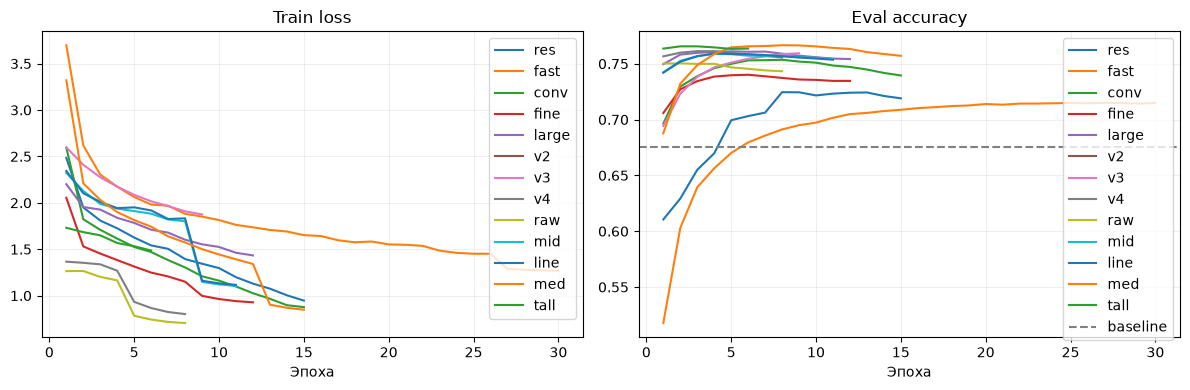

In [33]:
logs = {}
with (out/'log.csv').open(encoding='utf-8') as f:
    for row in csv.DictReader(f):
        logs.setdefault(row['model'],[]).append(row)
if learn:
    for a in jobs:
        p = out/(a['name']+'.csv')
        if p.exists():
            with p.open(encoding='utf-8') as f:
                logs[a['name']] = list(csv.DictReader(f))
for name,rows in logs.items():
    best = max(max(float(r['eval_acc']),float(r['ema_acc'])) for r in rows)
    print(name,'epochs',len(rows),'best eval',round(best,6))

fig,ax = plt.subplots(1,2,figsize=(12,4))
for name,rows in logs.items():
    epochs = [int(r['epoch']) for r in rows]
    ax[0].plot(epochs,[float(r['loss']) for r in rows],label=name)
    ax[1].plot(epochs,[max(float(r['eval_acc']),float(r['ema_acc'])) for r in rows],label=name)
ax[0].set_title('Train loss')
ax[1].set_title('Eval accuracy')
ax[1].axhline(base,color='gray',linestyle='--',label='baseline')
for a in ax:
    a.set_xlabel('Эпоха')
    a.legend()
    a.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Размер картинки

Проверяю разные размеры на 12000 картинках eval без нового обучения.

In [34]:
if learn:
    ids = np.random.default_rng(42).choice(split['ev'],12000,replace=False)
    v0 = torch.from_numpy(np.array(val[ids],copy=True)).cuda()
    y0 = z[ids]
    w = torch.load(out/'conv.pt',map_location='cpu',weights_only=True)
    a = w['config'].copy()
    m = make(a).cuda().to(memory_format=torch.channels_last)
    m.load_state_dict(w['model'])
    del w
    rows = []
    for size,view in [(64,'center'),(64,'raw'),(80,'center'),(96,'center'),
                      (128,'center'),(96,'raw'),(128,'raw')]:
        a['size'],a['view'] = size,view
        p0 = predict(m,v0,a,batch=128)
        acc = float((p0.argmax(1)==y0).mean())
        rows.append([size,view,len(y0),acc])
        print(size,view,round(acc,6))
    with (out/'size.csv').open('w',newline='',encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['size','view','eval_n','accuracy'])
        writer.writerows(rows)
    del m,v0,p0
else:
    with (out/'size.csv').open(encoding='utf-8') as f:
        for row in csv.DictReader(f):
            print(row['size'],row['view'],round(float(row['accuracy']),6))


64 center 0.751667
64 raw 0.744167
80 center 0.652833
96 center 0.319167
128 center 0.027
96 raw 0.279833
128 raw 0.035083


## 9. Итог

Усредняю вероятности моделей. Коэффициенты и обработку картинок выбираю по eval. Температура меняет уверенность модели и тоже выбирается на eval. Потом проверяю готовое решение на test и сохраняю CSV для Kaggle.

In [35]:
def load(path):
    w = torch.load(path,map_location='cpu',weights_only=True)
    m = make(w['config']).cuda().to(memory_format=torch.channels_last)
    m.load_state_dict(w['model'])
    return m, w['config']

def select(data, out, names, fast=False):
    if not learn:
        chosen = json.loads((Path(out)/'choice.json').read_text(encoding='utf-8'))
        assert abs(sum(a['weight'] for a in chosen['models'])-1)<1e-8
        for item in chosen['models']:
            p = Path(out)/(item['name']+'.pt')
            assert hashlib.sha256(p.read_bytes()).hexdigest()==item['sha256'], p.name
        return chosen
    assert 1 <= len(names) <= 12
    data, out = Path(data),Path(out)
    key = {'models':{name:hashlib.sha256((out/(name+'.pt')).read_bytes()).hexdigest() for name in names},
           'split':hashlib.sha256((out/'split.npz').read_bytes()).hexdigest(),
           'data':hashlib.sha256((out/'data.json').read_bytes()).hexdigest(),
           'method':'flip2g' if fast else 'tta5g'}
    file = out/'choice.json'
    if file.exists():
        old = json.loads(file.read_text(encoding='utf-8'))
        if old.get('key')==key and old.get('names')==names:
            valid = True
            for item in old['models']:
                p = out/(item['name']+'.pt')
                if not p.exists() or hashlib.sha256(p.read_bytes()).hexdigest()!=item['sha256']:
                    valid = False
                    break
            if valid:
                print('Сохранённый выбор по eval:',old['eval_acc'],flush=True)
                return old
    split = np.load(out/'split.npz')
    val = np.load(data/'val_images.npy',mmap_mode='r')
    labels = np.load(data/'val_labels.npy')
    classes = np.load(data/'classes.npy')
    ids = np.random.default_rng(42).choice(split['tr'],min(65536,len(split['tr'])),replace=False)
    train = np.load(data/'train_images.npy',mmap_mode='r')[ids]
    y = labels[split['ev']]
    options, probs = [], []
    for name in names:
        path = out/(name+'.pt')
        m,a = load(path)
        x = val[split['ev']]
        p = predict(m,x,a)
        before = float((p.argmax(1)==y).mean())
        p0 = p
        after = before
        if not fast:
            calibrate(m,train,a)
            p = predict(m,x,a)
            after = float((p.argmax(1)==y).mean())
        if after > before:
            name = name+'b'
            path = out/(name+'.pt')
            w = torch.load(out/(name[:-1]+'.pt'),map_location='cpu',weights_only=True)
            w['model'] = {k:v.detach().cpu() for k,v in m.state_dict().items()}
            w['bn_n'], w['eval_acc'] = len(train),after
            torch.save(w,path)
            del w
        else:
            del m
            m,a = load(path)
            p = p0
        best = -1
        scores = {}
        modes = [(False,False,False,False),(True,False,False,False),
                 (True,True,False,False),(True,False,True,False),(True,False,False,True)]
        if fast:
            modes = modes[:2]
        for flip,shift,rot,zoom in modes:
            if not (flip or shift or rot or zoom):
                q = p
            else:
                q = predict(m,x,a,flip=flip,shift=shift,rot=rot,zoom=zoom)
            acc = float((q.argmax(1)==y).mean())
            scores[str((flip,shift,rot,zoom))] = acc
            if acc > best:
                best,p,use_flip,use_shift,use_rot,use_zoom = acc,q,flip,shift,rot,zoom
        loss = float('inf')
        temp = 1.
        for t in [0.6,0.8,1.,1.2,1.4]:
            q = np.maximum(p,1e-8)**(1/t)
            q /= q.sum(1,keepdims=True)
            value = float(-np.log(q[np.arange(len(y)),y]).mean())
            if value < loss:
                loss,temp = value,t
        p = np.maximum(p,1e-8)**(1/temp)
        p /= p.sum(1,keepdims=True)
        item = {'name':name,'flip':bool(use_flip),'shift':bool(use_shift),
                'rot':bool(use_rot),'zoom':bool(use_zoom),
                'temperature':temp,'weight':1.0,'eval_acc':best,'eval_loss':loss,
                'bn_before':before,'bn_after':after,
                'tta':scores,'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
        print(item,flush=True)
        options.append(item)
        probs.append(p)
        del m
    best = -1
    weights = None
    trials = []
    grid = [[]]
    for i in range(len(names)):
        new = []
        for ws in grid:
            for w in range(11-sum(ws)):
                new.append(ws+[w])
        grid = new
    grid = [[w/10 for w in ws] for ws in grid if sum(ws)==10]
    q = torch.from_numpy(np.stack(probs)).cuda().flatten(1)
    truth = torch.from_numpy(y).cuda()
    counts = []
    tf32 = torch.backends.cuda.matmul.allow_tf32
    torch.backends.cuda.matmul.allow_tf32 = False
    try:
        for i in range(0,len(grid),32):
            w = torch.tensor(grid[i:i+32],device='cuda')
            p = (w@q).reshape(len(w),len(y),len(classes))
            n = (p.argmax(2)==truth[None]).sum(1)
            counts.extend(n.cpu().tolist())
    finally:
        torch.backends.cuda.matmul.allow_tf32 = tf32
    del q,truth,p,w
    trials = [{'weights':ws,'eval_acc':n/len(y)} for ws,n in zip(grid,counts)]
    for i in np.argsort(counts)[-20:]:
        ws = grid[int(i)]
        p = sum(float(w)*q for w,q in zip(ws,probs))
        acc = float((p.argmax(1)==y).mean())
        trials[int(i)]['eval_acc'] = acc
        if acc > best:
            best,weights = acc,ws
    for item,w in zip(options,weights):
        item['weight'] = float(w)
    chosen = {'eval_acc':best,'models':options,'trials':trials,'key':key,'names':names}
    (out/'choice.json').write_text(json.dumps(chosen,indent=2),encoding='utf-8')
    return chosen


In [36]:
def infer(x, out, options, classes):
    out = Path(out)
    models = []
    for item in options:
        if item['weight'] > 0:
            m,a = load(out/(item['name']+'.pt'))
            models.append((m,a,item))
    result = []
    for i in range(0,len(x),4096):
        b = x[i:i+4096]
        total = np.zeros((len(b),classes),dtype=np.float32)
        for m,a,item in models:
            p = predict(m,b,a,flip=item['flip'],shift=item['shift'],
                        rot=item.get('rot',False),zoom=item.get('zoom',False))
            p = np.maximum(p,1e-8)**(1/item['temperature'])
            p /= p.sum(1,keepdims=True)
            total += item['weight']*p
        result.append(total.argmax(1))
        print('pred',min(i+len(b),len(x)),'/',len(x),flush=True)
    return np.concatenate(result)

def save_csv(data, out, chosen):
    data, out = Path(data),Path(out)
    classes = len(np.load(data/'classes.npy'))
    x = np.load(data/'test_images.npy',mmap_mode='r')
    pred = infer(x,out,chosen['models'],classes)
    assert len(pred)==len(x) and pred.min()>=0 and pred.max()<classes
    with (out/'submission.csv').open('w',newline='',encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['id','label'])
        writer.writerows(enumerate(pred.tolist()))
    return len(pred)

def finish(data, out, names):
    data, out = Path(data),Path(out)
    chosen = select(data,out,names)
    options = chosen['models']
    best = chosen['eval_acc']
    split = np.load(out/'split.npz')
    val = np.load(data/'val_images.npy',mmap_mode='r')
    labels = np.load(data/'val_labels.npy')
    classes = np.load(data/'classes.npy')
    check = infer(val[split['ev']],out,options,len(classes))
    eval_acc = float((check==labels[split['ev']]).mean())
    pred = infer(val[split['te']],out,options,len(classes))
    truth = labels[split['te']]
    acc = float((pred==truth).mean())
    n = len(truth)
    report = {'eval_acc':eval_acc,'selection_eval_acc':best,'test_acc':acc,'test_n':n,
              'test_correct':int((pred==truth).sum()),
              'kaggle_score':None}
    saved = json.loads((out/'score.json').read_text(encoding='utf-8'))
    report['baseline_eval_acc'] = saved['baseline_eval_acc']
    report['baseline_test_acc'] = saved['baseline_test_acc']
    np.savez(out/'test.npz',truth=truth,pred=pred,ids=split['te'])
    cm = np.bincount(truth*len(classes)+pred,minlength=len(classes)**2).reshape(len(classes),-1)
    np.save(out/'cm.npy',cm)
    with (out/'classes.csv').open('w',newline='',encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['id','class','n','correct','accuracy'])
        for i,name in enumerate(classes):
            writer.writerow([i,str(name),int(cm[i].sum()),int(cm[i,i]),float(cm[i,i]/cm[i].sum())])
    report['submission_rows'] = save_csv(data,out,chosen)
    report['csv_sha256'] = hashlib.sha256((out/'submission.csv').read_bytes()).hexdigest()
    if saved['csv_sha256']==report['csv_sha256']:
        report['kaggle_score'] = saved['kaggle_score']
    (out/'score.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print(json.dumps(report,indent=2),flush=True)
    return report


In [37]:
chosen = ['fine', 'conv', 'large', 'v3', 'v4', 'raw', 'mid', 'line', 'med', 'emix', 'lmix', 'tall']
choice = select(data,out,chosen)
print('Best eval:',choice['eval_acc'])

Best eval: 0.7792702253488462


In [38]:
if calc or learn:
    score = finish(data,out,chosen)
else:
    score = json.loads((out/'score.json').read_text(encoding='utf-8'))
    assert hashlib.sha256((out/'submission.csv').read_bytes()).hexdigest()==score['csv_sha256']
    print('Сохранённые результаты:')
    print(json.dumps(score,indent=2))


Сохранённые результаты:
{
  "eval_acc": 0.7792895520080398,
  "selection_eval_acc": 0.7792702253488462,
  "test_acc": 0.7806013991419627,
  "test_n": 51746,
  "test_correct": 40393,
  "kaggle_score": 0.777,
  "baseline_test_acc": 0.6810574730413945,
  "submission_rows": 172500,
  "csv_sha256": "d3c027b7e429d481763b4a4f49898a0b8301777db2b6380ddf40a0bfd30ba03d",
  "baseline_eval_acc": 0.6751768389316223
}


### Ошибки на test

Смотрю их после выбора решения.

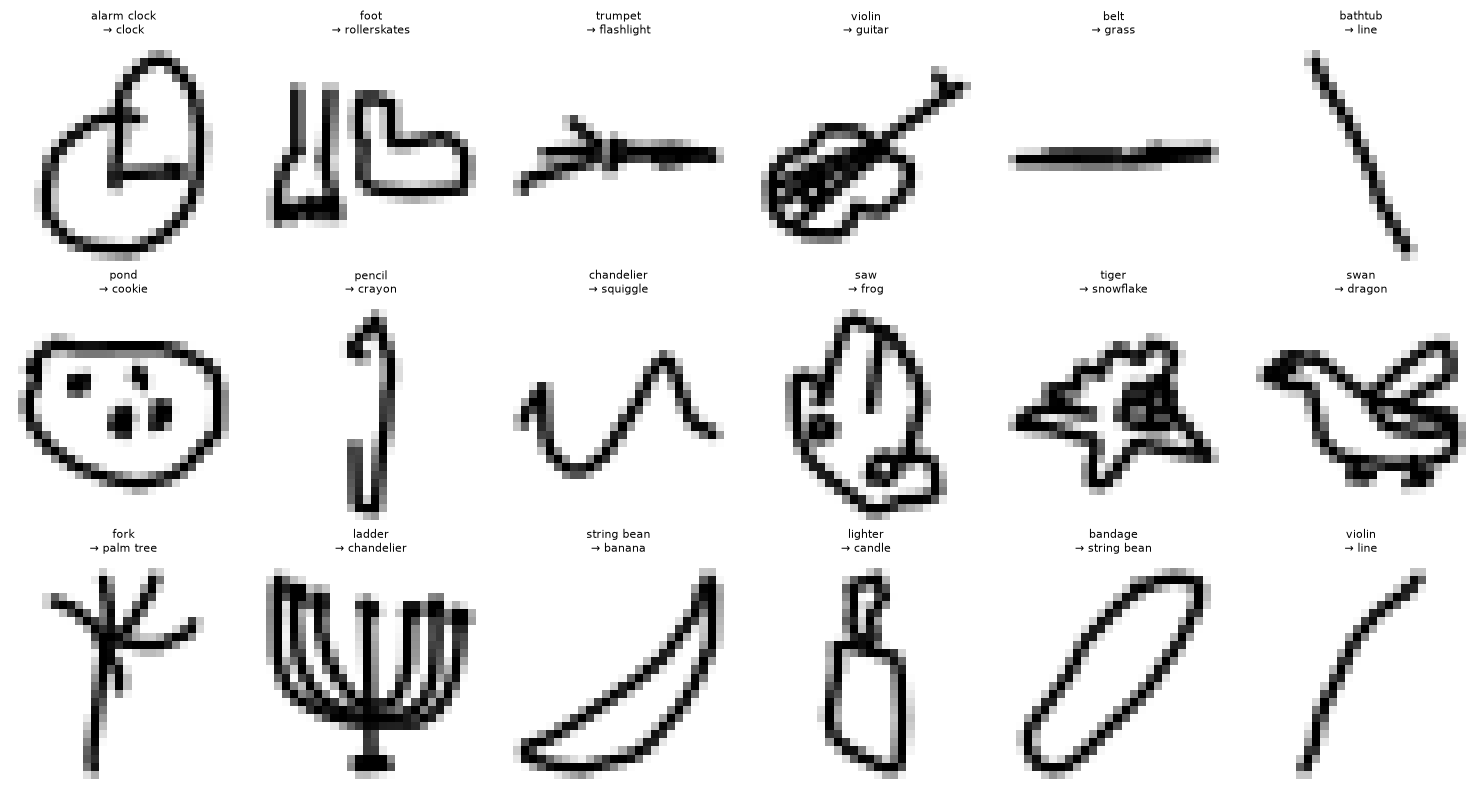

hurricane → tornado 58
cup → mug 44
school bus → bus 41
birthday cake → cake 40
octagon → hexagon 40
coffee cup → mug 39
cake → birthday cake 39
motorbike → bicycle 33
bus → school bus 32
telephone → cell phone 32


In [39]:
r = np.load(out/'test.npz')
bad = np.flatnonzero(r['truth']!=r['pred'])
ids = np.random.default_rng(42).choice(bad,min(18,len(bad)),replace=False)
fig,ax = plt.subplots(3,6,figsize=(15,8))
for a in ax.flat:
    a.axis('off')
for a,i in zip(ax.flat,ids):
    a.imshow(val[r['ids'][i]].reshape(28,28),cmap='gray_r')
    a.set_title(str(names[r['truth'][i]])+'\n→ '+str(names[r['pred'][i]]),fontsize=8)
plt.tight_layout()
plt.show()

cm = np.bincount(r['truth']*len(names)+r['pred'],minlength=len(names)**2).reshape(len(names),-1)
np.fill_diagonal(cm,0)
for i in np.argsort(cm.ravel())[-10:][::-1]:
    a,b = divmod(int(i),len(names))
    print(names[a],'→',names[b],int(cm[a,b]))


## 10. Источники

- Лекции 2–4.
- [Правила](https://www.kaggle.com/competitions/quick-draw-challenge-autumn-2026/rules).
- [ConvNeXt](https://arxiv.org/abs/2201.03545), [EfficientNetV2](https://arxiv.org/abs/2104.00298), [FasterNet](https://openaccess.thecvf.com/content/CVPR2023/html/Chen_Run_Dont_Walk_Chasing_Higher_FLOPS_for_Faster_Neural_Networks_CVPR_2023_paper.html).
- [Model Soups](https://arxiv.org/abs/2203.05482), [калибровка](https://arxiv.org/abs/1706.04599).
- PyTorch: [обучение](https://pytorch.org/blog/how-to-train-state-of-the-art-models-using-torchvision-latest-primitives/), [AMP](https://docs.pytorch.org/tutorials/recipes/recipes/amp_recipe.html), [EMA и BatchNorm](https://docs.pytorch.org/docs/2.7/optim.html#taking-care-of-batch-normalization).
